## Business Problem

Online learning platforms lose many learners before course completion, resulting in lower completion rates and lost potential subscription revenue, especially when free-trial users fail to convert into paid subscribers. This also wastes content development and marketing investments. The project aims to identify at-risk learners early using their learning activities and engagement data so the platform can improve retention and increase revenue.

## Data Understanding

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,KFold,cross_val_score,StratifiedKFold,cross_val_score
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,PowerTransformer,OneHotEncoder,OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,recall_score, roc_auc_score,precision_score
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import VarianceThreshold,RFE
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier
from sklearn.svm import SVC
import optuna
from sklearn.naive_bayes import GaussianNB,MultinomialNB,ComplementNB,CategoricalNB
from imblearn.over_sampling import SMOTE,ADASYN
from collections import Counter
from mlxtend.evaluate import bias_variance_decomp
import pickle
import sklearn
import xgboost
import imblearn

In [2]:
df=pd.read_csv(r"C:\Users\Ganesh\Downloads\mooc_learner_dropout.csv")

In [3]:
df

,learner_id,age,gender,education_level,employment_status,primary_device,course_category,course_level,is_paid_course,course_price_inr,...,previous_courses_completed,avg_weekly_logins,total_watch_minutes,video_completion_pct,avg_quiz_score,assignment_submission_pct,forum_posts,avg_submission_delay_days,timezone_region,dropped_out
0,LN300000,29,Female,High School,Student,Laptop,Business,Beginner,0,0.0,...,0,2.3,210.0,14.3,77.7,78.4,0,1.4,Europe,1
1,LN300001,23,Female,Bachelors,Employed,Laptop,Data Science,Intermediate,1,464.0,...,2,5.9,78.0,71.2,NaN,24.7,1,3.3,Africa,1
2,LN300002,24,NaN,High School,Student,Laptop,Web Dev,Beginner,1,1777.0,...,1,11.7,355.0,79.9,100.0,57.0,1,1.5,Asia,0
3,LN300003,15,Female,Masters,Employed,Laptop,Data Science,Intermediate,0,0.0,...,1,8.1,39.0,89.0,53.0,56.3,0,NaN,Asia,0
4,LN300004,41,Female,NaN,Student,Mobile,Business,Beginner,0,0.0,...,2,1.7,47.0,61.9,70.1,60.8,1,2.9,Asia,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51995,LN351995,19,Female,Diploma,Student,Laptop,Business,Intermediate,0,0.0,...,1,5.2,247.0,19.6,64.5,58.2,0,7.8,Africa,1
51996,LN351996,28,Male,Bachelors,Unemployed,Tablet,Languages,Intermediate,0,0.0,...,1,0.4,210.0,69.1,43.7,71.0,0,1.2,Europe,0
51997,LN351997,23,Male,Bachelors,Student,Mobile,Business,Beginner,0,0.0,...,2,1.8,240.0,51.1,NaN,67.4,1,0.8,Asia,0
51998,LN351998,37,Male,High School,Self-employed,Mobile,Data Science,Intermediate,0,0.0,...,3,1.8,293.0,88.1,60.5,9.1,1,3.4,Europe,0


In [4]:
df['course_category'].unique()

array(['Business', 'Data Science', 'Web Dev', 'Languages', 'Finance',
       'Health', 'Design', 'Cybersecurity'], dtype=object)

In [5]:
df['dropped_out'].value_counts()

dropped_out
0    34320
1    17680
Name: count, dtype: int64

In [6]:
df.drop(columns=['age','gender','learner_id','timezone_region','education_level',
                 'is_paid_course','forum_posts','previous_courses_completed','employment_status'],inplace=True)

In [7]:
df

,primary_device,course_category,course_level,course_price_inr,course_duration_weeks,avg_weekly_logins,total_watch_minutes,video_completion_pct,avg_quiz_score,assignment_submission_pct,avg_submission_delay_days,dropped_out
0,Laptop,Business,Beginner,0.0,12,2.3,210.0,14.3,77.7,78.4,1.4,1
1,Laptop,Data Science,Intermediate,464.0,8,5.9,78.0,71.2,NaN,24.7,3.3,1
2,Laptop,Web Dev,Beginner,1777.0,10,11.7,355.0,79.9,100.0,57.0,1.5,0
3,Laptop,Data Science,Intermediate,0.0,6,8.1,39.0,89.0,53.0,56.3,NaN,0
4,Mobile,Business,Beginner,0.0,12,1.7,47.0,61.9,70.1,60.8,2.9,1
...,...,...,...,...,...,...,...,...,...,...,...,...
51995,Laptop,Business,Intermediate,0.0,8,5.2,247.0,19.6,64.5,58.2,7.8,1
51996,Tablet,Languages,Intermediate,0.0,16,0.4,210.0,69.1,43.7,71.0,1.2,0
51997,Mobile,Business,Beginner,0.0,12,1.8,240.0,51.1,NaN,67.4,0.8,0
51998,Mobile,Data Science,Intermediate,0.0,12,1.8,293.0,88.1,60.5,9.1,3.4,0


In [8]:
df.shape

(52000, 12)

In [9]:
df.columns

Index(['primary_device', 'course_category', 'course_level', 'course_price_inr',
       'course_duration_weeks', 'avg_weekly_logins', 'total_watch_minutes',
       'video_completion_pct', 'avg_quiz_score', 'assignment_submission_pct',
       'avg_submission_delay_days', 'dropped_out'],
      dtype='object')

In [10]:
df.dtypes

primary_device                object
course_category               object
course_level                  object
course_price_inr             float64
course_duration_weeks          int64
avg_weekly_logins            float64
total_watch_minutes          float64
video_completion_pct         float64
avg_quiz_score               float64
assignment_submission_pct    float64
avg_submission_delay_days    float64
dropped_out                    int64
dtype: object

In [11]:
df['course_category'].unique()

array(['Business', 'Data Science', 'Web Dev', 'Languages', 'Finance',
       'Health', 'Design', 'Cybersecurity'], dtype=object)

In [12]:
df.describe(include='all')

,primary_device,course_category,course_level,course_price_inr,course_duration_weeks,avg_weekly_logins,total_watch_minutes,video_completion_pct,avg_quiz_score,assignment_submission_pct,avg_submission_delay_days,dropped_out
count,52000,52000,52000,52000.000000,52000.000000,52000.000000,52000.000000,49478.000000,45715.000000,52000.000000,47890.000000,52000.000000
unique,3,8,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Laptop,Web Dev,Beginner,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,25000,10453,28846,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,669.998923,9.358423,4.434723,226.676837,54.906251,61.884561,44.395587,3.008973,0.340000
std,NaN,NaN,NaN,1288.244448,3.938858,3.246399,259.670619,22.250257,18.617278,21.183964,3.008865,0.473713
min,NaN,NaN,NaN,0.000000,4.000000,0.000000,3.000000,0.500000,0.000000,0.100000,0.000000,0.000000
25%,NaN,NaN,NaN,0.000000,6.000000,2.100000,81.000000,38.100000,49.200000,27.900000,0.900000,0.000000
50%,NaN,NaN,NaN,0.000000,10.000000,3.700000,150.000000,55.700000,62.200000,43.400000,2.100000,0.000000
75%,NaN,NaN,NaN,1007.250000,12.000000,5.900000,276.000000,72.700000,74.900000,60.100000,4.200000,1.000000


In [13]:
df['course_price_inr'].min()

0.0

In [14]:
df['course_price_inr'].max()

21668.0

In [15]:
df.isna().sum()

primary_device                  0
course_category                 0
course_level                    0
course_price_inr                0
course_duration_weeks           0
avg_weekly_logins               0
total_watch_minutes             0
video_completion_pct         2522
avg_quiz_score               6285
assignment_submission_pct       0
avg_submission_delay_days    4110
dropped_out                     0
dtype: int64

### Problem: Classification, because the output column represents a binary classification problem.

In [7]:
X=df.drop(columns=['dropped_out'])#X is input columns.
y=df['dropped_out']#y is output column.

In [17]:
X.shape

(52000, 11)

In [18]:
y.shape

(52000,)

## Step-2:Data Preprocessing

#### Train Test Split(Splitting the data to prevent data leakage)

In [8]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=23)

In [20]:
X_train.shape

(41600, 11)

In [21]:
X_test.shape

(10400, 11)

In [22]:
y_train.shape

(41600,)

In [23]:
y_test.shape

(10400,)

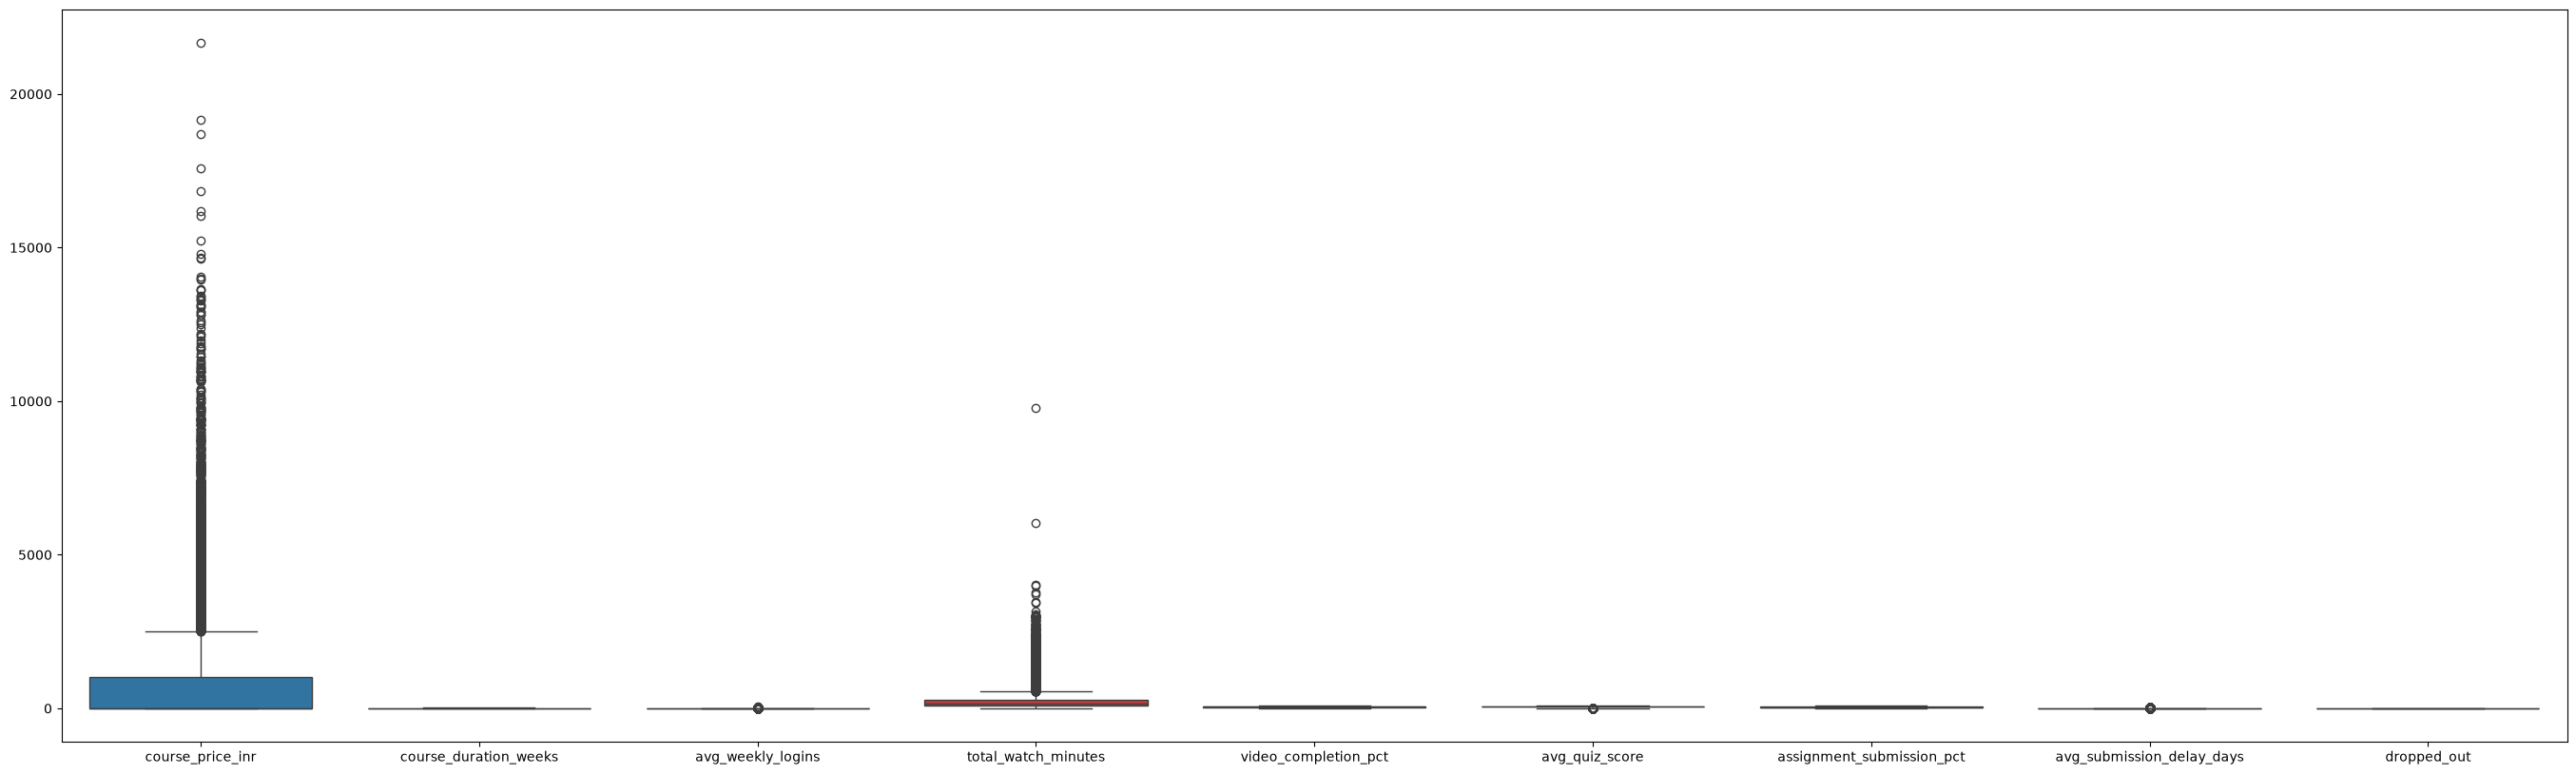

In [24]:
plt.figure(figsize=(34,10))
sns.boxplot(df);

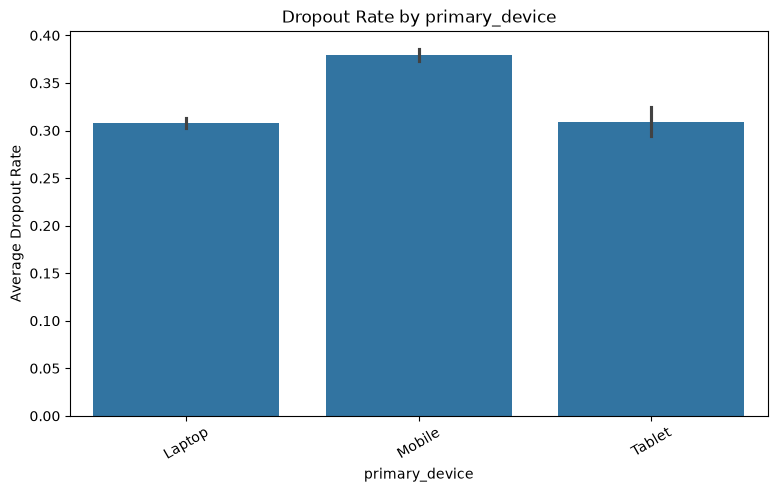

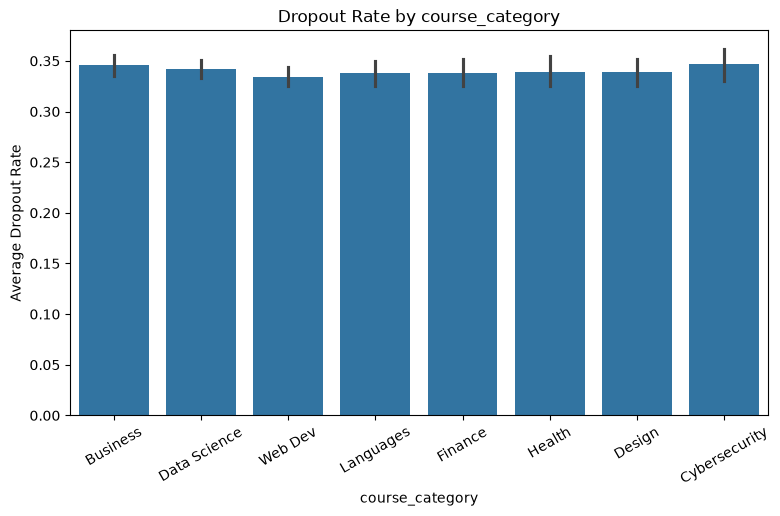

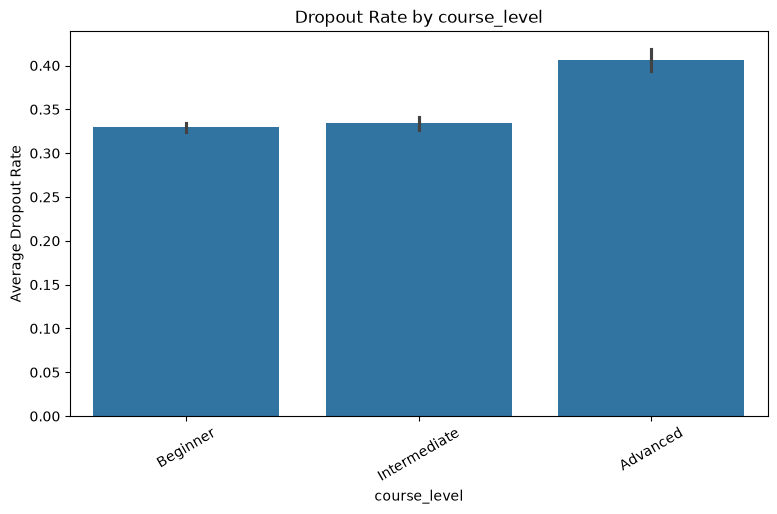

In [45]:
categorical_features = [
    'primary_device',
    'course_category',
    'course_level'
]

for col in categorical_features:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=df,
        x=col,
        y='dropped_out'
    )

    plt.title(f'Dropout Rate by {col}')
    plt.xlabel(col)
    plt.ylabel('Average Dropout Rate')
    plt.xticks(rotation=30)

    plt.show()

<Axes: xlabel='course_price_inr', ylabel='dropped_out'>

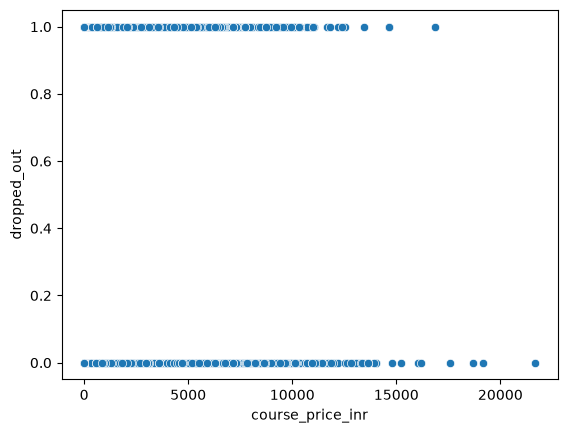

In [47]:
sns.scatterplot(data=df,x='course_price_inr',y='dropped_out')

<Axes: xlabel='dropped_out', ylabel='course_price_inr'>

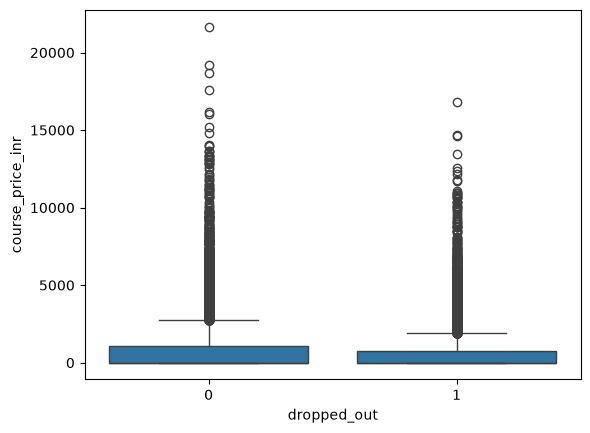

In [48]:
sns.boxplot(data=df, x='dropped_out', y='course_price_inr')

<Axes: xlabel='dropped_out', ylabel='course_price_inr'>

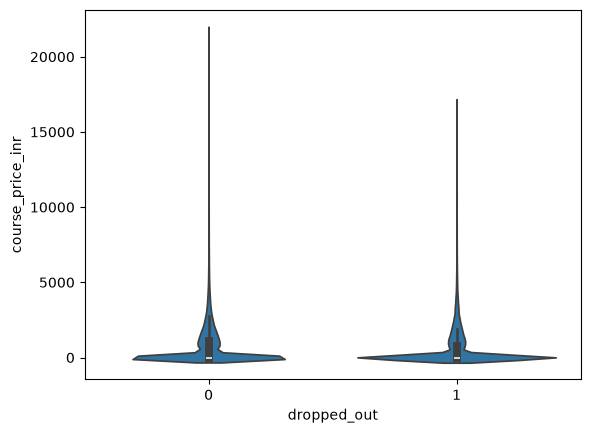

In [49]:
sns.violinplot(data=df, x='dropped_out', y='course_price_inr')

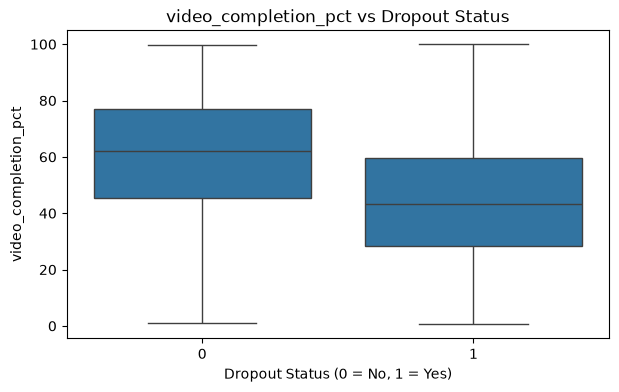

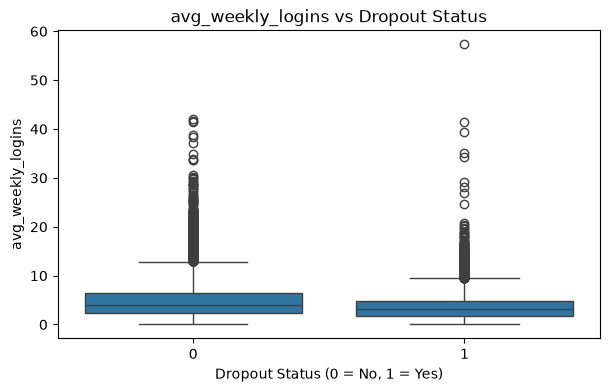

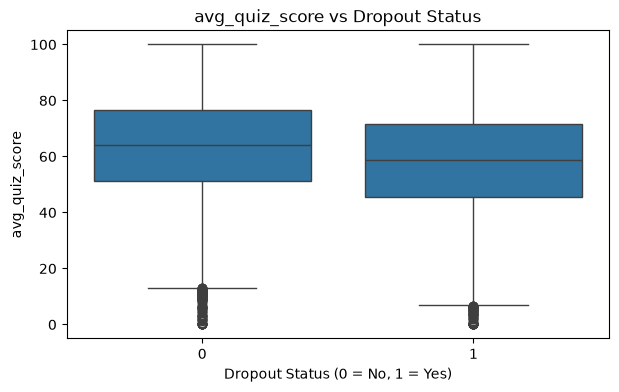

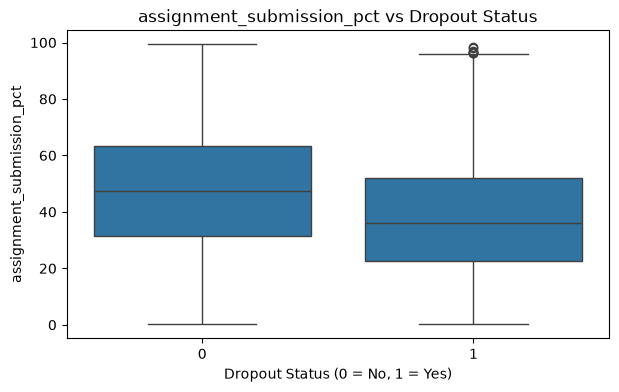

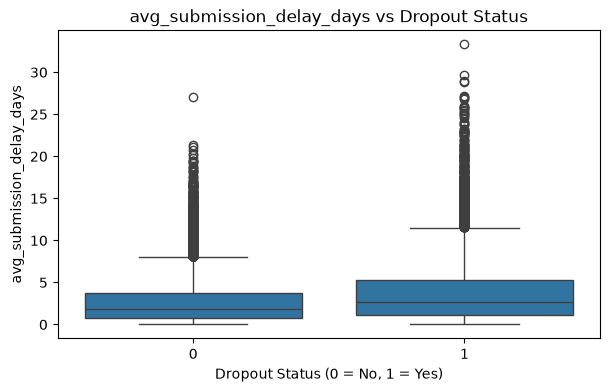

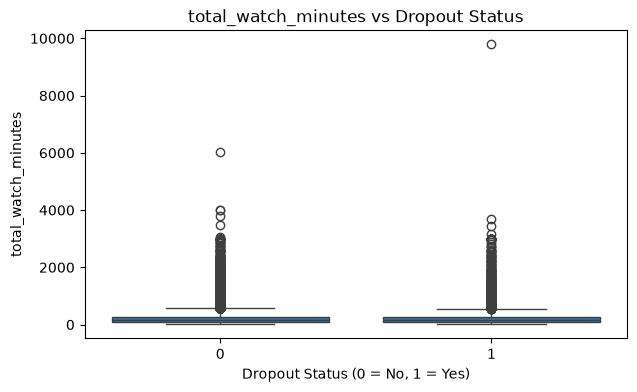

In [44]:
features = [
    'video_completion_pct',
    'avg_weekly_logins',
    'avg_quiz_score',
    'assignment_submission_pct',
    'avg_submission_delay_days',
    'total_watch_minutes'
]

for col in features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(data=df, x='dropped_out', y=col)

    plt.title(f'{col} vs Dropout Status')
    plt.xlabel('Dropout Status (0 = No, 1 = Yes)')
    plt.ylabel(col)

    plt.show()

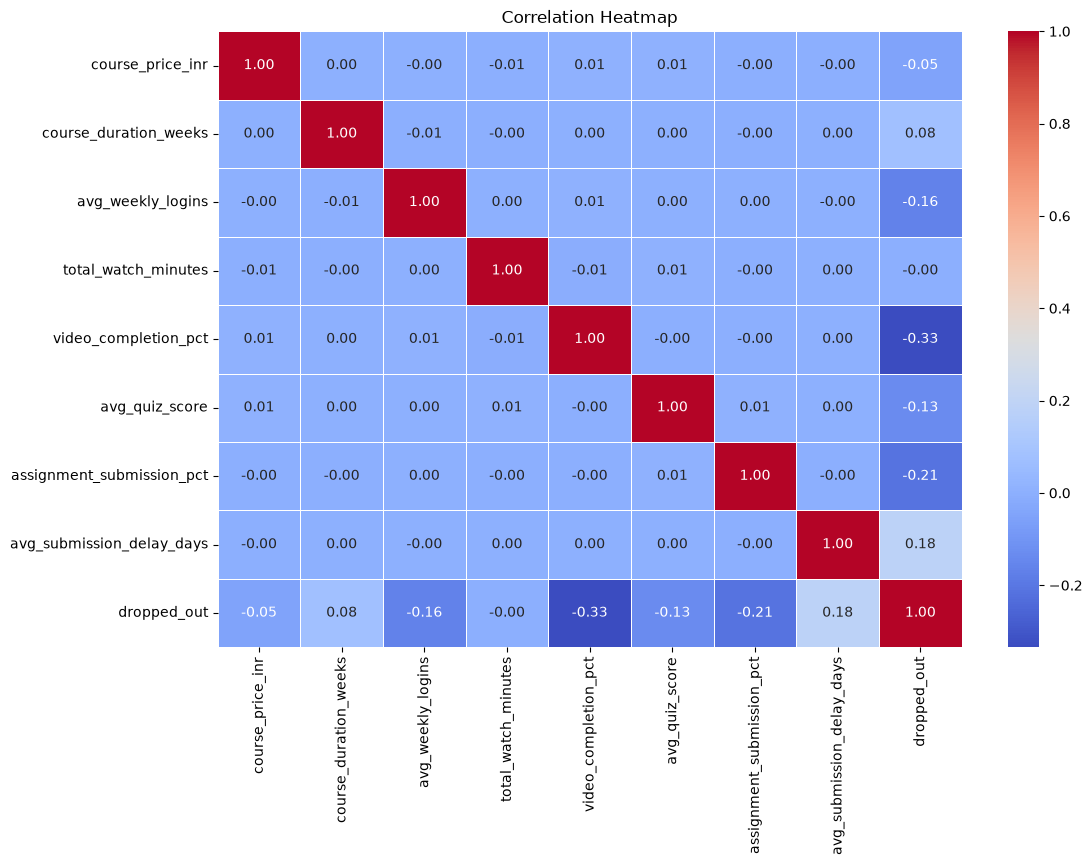

In [46]:
plt.figure(figsize=(12, 8))

corr = df.select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.show()

In [26]:
df['course_price_inr'].max()

21668.0

In [27]:
df['course_price_inr'].min()

0.0

In [28]:
df['avg_quiz_score'].min()

0.0

In [29]:
df['avg_quiz_score'].max()

100.0

In [30]:
df['avg_submission_delay_days'].min()

0.0

In [31]:
df['avg_submission_delay_days'].max()

33.3

In [32]:
df['total_watch_minutes'].mean()

np.float64(226.67683653846154)

In [33]:
df['total_watch_minutes'].min()

3.0

In [34]:
df['total_watch_minutes'].max()

9786.0

In [35]:
num_cols=df.select_dtypes(exclude='object').columns
num_cols

Index(['course_price_inr', 'course_duration_weeks', 'avg_weekly_logins',
       'total_watch_minutes', 'video_completion_pct', 'avg_quiz_score',
       'assignment_submission_pct', 'avg_submission_delay_days',
       'dropped_out'],
      dtype='object')

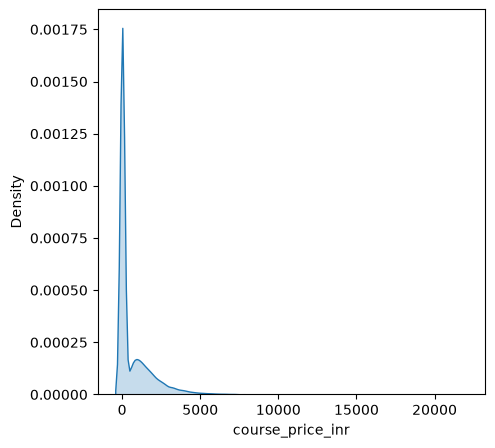

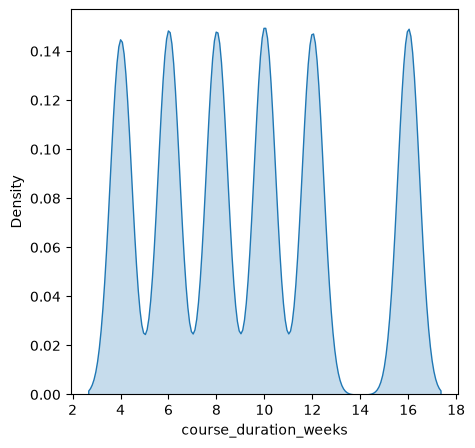

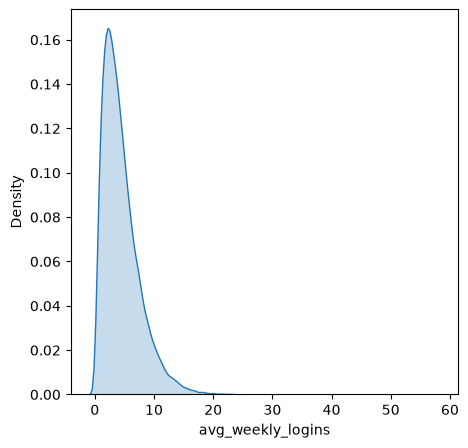

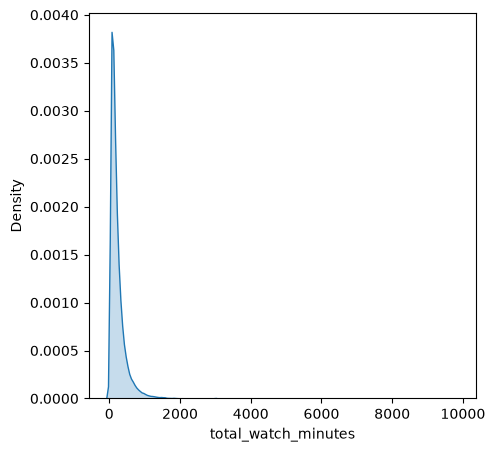

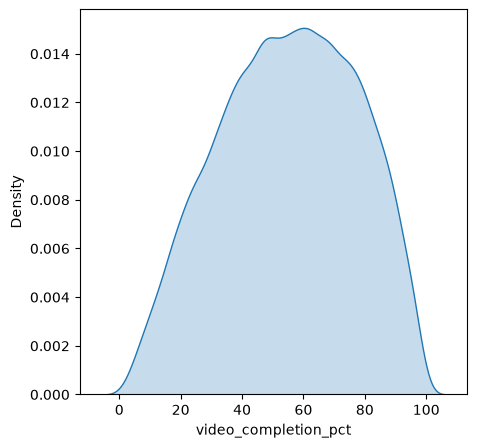

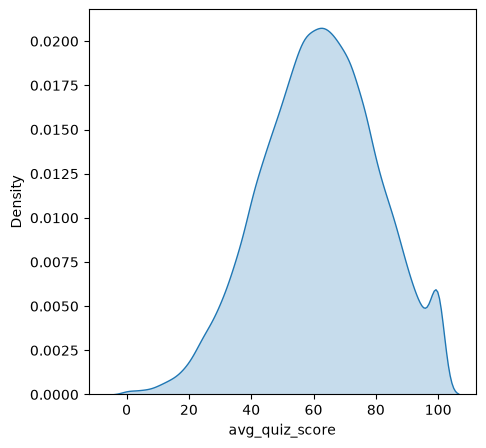

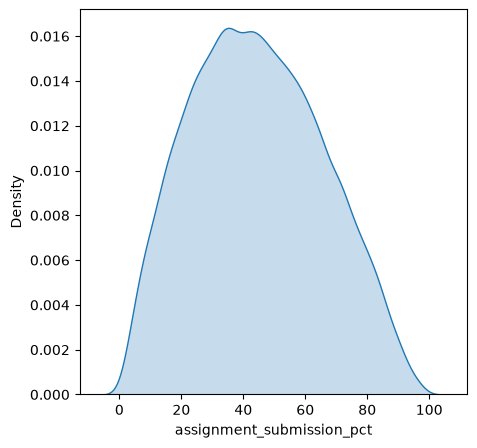

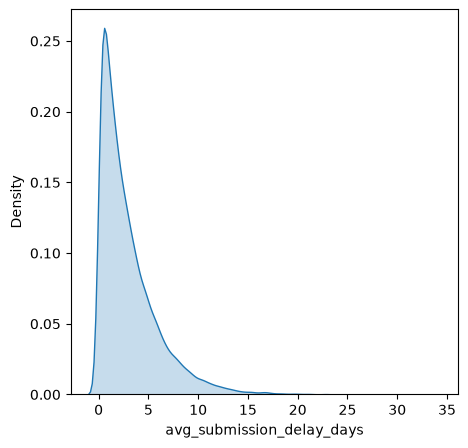

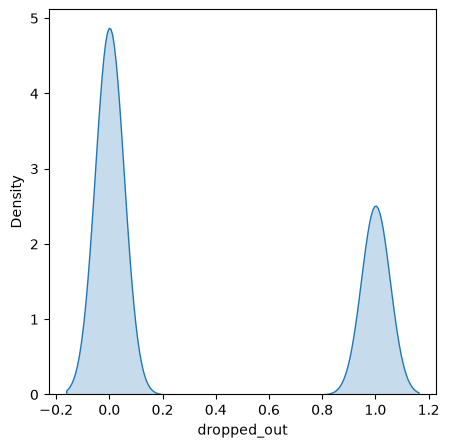

In [36]:
for i in num_cols:
    plt.figure(figsize=(5,5))
    sns.kdeplot(data=df,x=i,fill=True)

In [37]:
df.columns

Index(['primary_device', 'course_category', 'course_level', 'course_price_inr',
       'course_duration_weeks', 'avg_weekly_logins', 'total_watch_minutes',
       'video_completion_pct', 'avg_quiz_score', 'assignment_submission_pct',
       'avg_submission_delay_days', 'dropped_out'],
      dtype='object')

In [38]:
df.dtypes

primary_device                object
course_category               object
course_level                  object
course_price_inr             float64
course_duration_weeks          int64
avg_weekly_logins            float64
total_watch_minutes          float64
video_completion_pct         float64
avg_quiz_score               float64
assignment_submission_pct    float64
avg_submission_delay_days    float64
dropped_out                    int64
dtype: object

In [39]:
df['course_level'].unique()

array(['Beginner', 'Intermediate', 'Advanced'], dtype=object)

In [9]:
num_cols=['avg_weekly_logins','total_watch_minutes','video_completion_pct','avg_quiz_score',
         'assignment_submission_pct','course_price_inr','course_duration_weeks','avg_submission_delay_days']
nominal_cols=['course_category','primary_device']
ordinal_cols=['course_level']

In [10]:
ordinal_order=[['Beginner', 'Intermediate', 'Advanced']]

In [11]:
numeric_transformer=Pipeline([('Imputation',SimpleImputer(strategy='median',add_indicator=True)),
                             ('Scaling',StandardScaler()),
                             ('Transformation',PowerTransformer())])

In [12]:
numeric_transformer

,steps,"[('Imputation', ...), ('Scaling', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,True
,keep_empty_features,False
,copy,True


In [13]:
nominal_transformer=Pipeline([('Imputation',SimpleImputer(strategy='constant',fill_value='Missing')),
                             ('Encoding',OneHotEncoder())])

In [14]:
nominal_transformer

,steps,"[('Imputation', ...), ('Encoding', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'constant'
,fill_value,'Missing'
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


In [15]:
ordinal_transformer=Pipeline([('Imputation',SimpleImputer(strategy='most_frequent')),
                             ('Encoding',OrdinalEncoder(categories=ordinal_order))])

In [16]:
ordinal_transformer

,steps,"[('Imputation', ...), ('Encoding', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,"[['Beginner', 'Intermediate', ...]]"


In [17]:
preprocessing=ColumnTransformer([('Numerical Transformer',numeric_transformer,num_cols),
                                ('Nominal Transformer',nominal_transformer,nominal_cols),
                                ('Ordinal Transformer',ordinal_transformer,ordinal_cols)])

In [49]:
preprocessing

,transformers,"[('Numerical Transformer', ...), ('Nominal Transformer', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## Feature Selection

#### Checking variance of numerical features

In [26]:
a=X_train[num_cols].var()
b=a.astype(int)
b

age                                64
is_paid_course                      0
course_price_inr              1657159
course_duration_weeks              15
previous_courses_completed          1
avg_weekly_logins                  10
total_watch_minutes             67957
video_completion_pct              496
avg_quiz_score                    345
assignment_submission_pct         448
forum_posts                         1
avg_submission_delay_days           9
dtype: int64

In [27]:
vt=VarianceThreshold(threshold=10)
vt.fit_transform(X_train[num_cols])

array([[  31. ,  947. ,   10. , ...,   34.8,    nan,   56.6],
       [  37. , 3352. ,    4. , ...,   81.8,    nan,   74.2],
       [  33. ,    0. ,   10. , ...,   33.6,   71.2,   80.8],
       ...,
       [  37. ,    0. ,    4. , ...,   87.2,   47.4,   37.4],
       [  39. ,    0. ,   10. , ...,   25.2,   78.8,   71.8],
       [  27. ,    0. ,    8. , ...,   23.8,   76.5,   69.4]],
      shape=(41600, 8))

In [28]:
vt.get_feature_names_out()

array(['age', 'course_price_inr', 'course_duration_weeks',
       'avg_weekly_logins', 'total_watch_minutes', 'video_completion_pct',
       'avg_quiz_score', 'assignment_submission_pct'], dtype=object)

#### Wrapper Method

In [32]:
pipe1=Pipeline([('preprocessing',preprocessing),
               ('RFE',RFE(estimator=LogisticRegression(),n_features_to_select=15))])
pipe1.fit_transform(X_train,y_train)

array([[ 1.35660089,  0.26748084,  0.5667668 , ...,  0.        ,
         1.        ,  0.        ],
       [ 1.35660089, -1.49248612,  1.20514743, ...,  0.        ,
         0.        ,  1.        ],
       [-0.73713648,  0.26748084, -1.43658372, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [-0.73713648, -1.49248612, -1.43658372, ...,  0.        ,
         0.        ,  1.        ],
       [-0.73713648,  0.26748084, -1.43658372, ...,  0.        ,
         1.        ,  0.        ],
       [-0.73713648, -0.26047098, -1.43658372, ...,  0.        ,
         0.        ,  1.        ]], shape=(41600, 15))

In [33]:
pipe1.get_feature_names_out()

array(['Numerical Transformer__is_paid_course',
       'Numerical Transformer__course_duration_weeks',
       'Numerical Transformer__previous_courses_completed',
       'Numerical Transformer__avg_weekly_logins',
       'Numerical Transformer__video_completion_pct',
       'Numerical Transformer__avg_quiz_score',
       'Numerical Transformer__assignment_submission_pct',
       'Numerical Transformer__forum_posts',
       'Numerical Transformer__avg_submission_delay_days',
       'Nominal Transformer__employment_status_Employed',
       'Nominal Transformer__primary_device_Laptop',
       'Nominal Transformer__primary_device_Tablet',
       'Nominal Transformer__course_level_Advanced',
       'Nominal Transformer__course_level_Beginner',
       'Nominal Transformer__course_level_Intermediate'], dtype=object)

## Step-3:Model Building

### Logistic Regression

In [43]:
model1=Pipeline([('preprocessing',preprocessing),
                 ('SMOTE',SMOTE(random_state=23)),
                ('Logistic Regression',LogisticRegression(C= 0.05122152146266155, solver='liblinear', max_iter=300))])
model1.fit(X_train,y_train)
y_pred=model1.predict(X_test)
print('accuracy score',accuracy_score(y_test,y_pred))
print('f1 score',f1_score(y_test,y_pred))
print('recall',recall_score(y_test,y_pred))
print('precision',precision_score(y_test,y_pred))

accuracy score 0.7178846153846153
f1 score 0.6433260393873085
recall 0.7289256198347107
precision 0.5757180156657964


In [54]:
X_train_transformed=preprocessing.fit_transform(X_train)
X_test_transformed=preprocessing.transform(X_test)
avg_expected_loss,avg_bias,avg_var=bias_variance_decomp(LogisticRegression(C=4.7055294974265385,
                                                                           solver='liblinear',max_iter=700),
                                                        X_train_transformed,y_train,X_test_transformed,y_test)

In [55]:
avg_expected_loss

np.float64(0.2536548076923077)

In [56]:
avg_bias

np.float64(0.2536538461538462)

In [57]:
avg_var

np.float64(0.011452884615384615)

In [36]:
print('Train accuracy score',model1.score(X_train,y_train))
print('Test accuracy score',model1.score(X_test,y_test))

Train accuracy score 0.7199278846153846
Test accuracy score 0.7176923076923077


### XgBoost

In [27]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
scale_pos_weight

np.float64(1.9608540925266904)

In [30]:
model2=Pipeline([('preprocessing',preprocessing),
                 ('SMOTE',SMOTE(random_state=23)),
                ('XgBoost',XGBClassifier(n_estimators=450, max_depth= 2, learning_rate=0.04577249331614816, 
                                         subsample=0.7139680138843443, colsample_bytree= 0.8765893447263453, 
                                         min_child_weight=8, gamma= 4.6408870365892305, reg_lambda=4.283032614373939))])
model2.fit(X_train,y_train)
y_pred1=model2.predict(X_test)
print('accuracy score',accuracy_score(y_test,y_pred1))
print('f1 score',f1_score(y_test,y_pred1))
print('recall',recall_score(y_test,y_pred1))
print('precision',precision_score(y_test,y_pred1))

accuracy score 0.7308653846153846
f1 score 0.6302998282921675
recall 0.6573002754820937
precision 0.6054300938848008


In [63]:
skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=23)

In [64]:
cross_val_score(model2,X,y,scoring='recall',cv=skf)

array([0.50791855, 0.50480769, 0.51951357, 0.49745475, 0.50791855])

In [37]:
print('Train accuracy score',model2.score(X_train,y_train))
print('Test accuracy score',model2.score(X_test,y_test))

Train accuracy score 0.7438942307692308
Test accuracy score 0.7308653846153846


## Decision Tree

In [24]:
model3=Pipeline([('preprocessing',preprocessing),
                ('Decision Tree',DecisionTreeClassifier(criterion= 'gini', max_depth=7, 
                                                        min_samples_split=28, min_samples_leaf= 8, 
                                                        max_features=None, class_weight='balanced'))])
model3.fit(X_train,y_train)
y_pred2=model3.predict(X_test)
print('accuracy score',accuracy_score(y_test,y_pred2))
print('f1 score',f1_score(y_test,y_pred2))
print('precision',precision_score(y_test,y_pred2))
print('recall score',recall_score(y_test,y_pred2))

accuracy score 0.69125
f1 score 0.6076011242820482
precision 0.5460136173951241
recall score 0.6848484848484848


In [64]:
print('Train accuracy score',model3.score(X_train,y_train))
print('Test accuracy score',model3.score(X_test,y_test))

Train accuracy score 0.7124038461538461
Test accuracy score 0.6896153846153846


## Random Forest

In [25]:
model4=Pipeline([('preprocessing',preprocessing),
                ('Random Forest',RandomForestClassifier(n_estimators=450, max_depth=8, min_samples_split=30, 
                                                        min_samples_leaf=25, max_features='sqrt', 
                                                        class_weight='balanced_subsample'))])
model4.fit(X_train,y_train)
y_pred3=model4.predict(X_test)
print('accuracy score',accuracy_score(y_test,y_pred3))
print('f1 score',f1_score(y_test,y_pred3))
print('recall score',recall_score(y_test,y_pred3))
print('precision score',precision_score(y_test,y_pred3))

accuracy score 0.7141346153846154
f1 score 0.6363302752293578
recall score 0.7165289256198347
precision score 0.5722772277227722


In [56]:
print('Train accuracy score',model4.score(X_train,y_train))
print('Test accuracy score',model4.score(X_test,y_test))

Train accuracy score 0.7378365384615385
Test accuracy score 0.7138461538461538


In [57]:
skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=23)

In [58]:
cross_val_score(model4,X,y,scoring='recall',cv=skf)

array([0.69739819, 0.70418552, 0.72794118, 0.70192308, 0.71634615])

## SVC

In [34]:
model5=Pipeline([('preprocessing',preprocessing),
                 ('SMOTE',SMOTE(random_state=23)),
                ('SVC',SVC())])
model5.fit(X_train,y_train)
y_pred4=model5.predict(X_test)
print('accuracy score',accuracy_score(y_test,y_pred4))
print('f1 score',f1_score(y_test,y_pred4))
print('recall score',recall_score(y_test,y_pred4))
print('precision',precision_score(y_test,y_pred4))

accuracy score 0.708173076923077
f1 score 0.6332326283987916
recall score 0.721763085399449
precision 0.5640473627556513


In [35]:
print('Train accuracy score',model5.score(X_train,y_train))
print('Test accuracy score',model5.score(X_test,y_test))

Train accuracy score 0.7426201923076923
Test accuracy score 0.708173076923077


## Naive Bayes

In [31]:
model6=Pipeline([('preprocessing',preprocessing),
                 ('SMOTE',SMOTE(random_state=23)),
                ('Naive Bayes',GaussianNB(var_smoothing= 8.421530714776686e-08))])
model6.fit(X_train,y_train)
y_pred5=model6.predict(X_test)
print('accuracy score',accuracy_score(y_test,y_pred5))
print('f1 score',f1_score(y_test,y_pred5))
print('recall score',recall_score(y_test,y_pred5))
print('precision',precision_score(y_test,y_pred5))

accuracy score 0.6943269230769231
f1 score 0.6213222156045265
recall score 0.718457300275482
precision 0.547324239244491


In [32]:
print('Train accuracy score',model6.score(X_train,y_train))
print('Test accuracy score',model6.score(X_test,y_test))

Train accuracy score 0.694375
Test accuracy score 0.6943269230769231


In [22]:

# Create an Objective Function

def Objective_NB(trial):

    # Creating Search Space
    var_smoothing = trial.suggest_float(
        'var_smoothing', 1e-12, 1e-6, log=True
    )

    # Training the Model
    nb = Pipeline([
        ('preprocessing', preprocessing),
        ('Naive Bayes', GaussianNB(
            var_smoothing=var_smoothing
        ))
    ])

    kf = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=23
    )

    # Scoring
    score = cross_val_score(
        nb, X_train, y_train,
        cv=kf, scoring='f1'
    ).mean()

    return score


# Create the Study

study_nb = optuna.create_study(direction='maximize')


# Evaluate

study_nb.optimize(Objective_NB, n_trials=100)

[I 2026-11-02 17:28:37,595] A new study created in memory with name: no-name-3ab3c613-bd4d-4caa-803b-d87253142bca
[I 2026-11-02 17:28:52,189] Trial 0 finished with value: 0.5697062116992416 and parameters: {'var_smoothing': 1.7768586671341987e-11}. Best is trial 0 with value: 0.5697062116992416.
[I 2026-11-02 17:29:07,090] Trial 1 finished with value: 0.5697062116992416 and parameters: {'var_smoothing': 3.6683990800003275e-10}. Best is trial 0 with value: 0.5697062116992416.
[I 2026-11-02 17:29:21,844] Trial 2 finished with value: 0.5697062116992416 and parameters: {'var_smoothing': 1.1693162185478246e-12}. Best is trial 0 with value: 0.5697062116992416.
[I 2026-11-02 17:29:36,640] Trial 3 finished with value: 0.5697062116992416 and parameters: {'var_smoothing': 6.552946108491456e-08}. Best is trial 0 with value: 0.5697062116992416.
[I 2026-11-02 17:29:51,386] Trial 4 finished with value: 0.5697062116992416 and parameters: {'var_smoothing': 2.773200310731278e-07}. Best is trial 0 with 

In [70]:
print('Train accuracy score',model6.score(X_train,y_train))
print('Test accuracy score',model6.score(X_test,y_test))

Train accuracy score 0.7431490384615385
Test accuracy score 0.7352884615384615


## Hyperparamter Tuning

In [38]:
# Create an Objective Function

def Objective(trial):

    # Creating Search Space
    C = trial.suggest_float('C', 0.01, 100, log=True)
    solver = trial.suggest_categorical('solver', ['lbfgs', 'liblinear'])
    max_iter = trial.suggest_int('max_iter', 100, 1000, step=100)

    # Training the Model
    lr = Pipeline([
        ('preprocessing', preprocessing),
        ('Logistic Regression', LogisticRegression(
            C=C,
            solver=solver,
            max_iter=max_iter
        ))
    ])

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)

    # Scoring
    score = cross_val_score(
        lr, X_train, y_train, cv=kf, scoring='f1'
    ).mean()

    return score


# Create the Study

study = optuna.create_study(direction='maximize')


# Evaluate

study.optimize(Objective, n_trials=100)

[I 2026-11-05 15:46:44,725] A new study created in memory with name: no-name-97e9fe17-c71f-41e0-b579-555d2adbf4ad
[I 2026-11-05 15:46:56,342] Trial 0 finished with value: 0.5755841913822102 and parameters: {'C': 0.01026189970476385, 'solver': 'liblinear', 'max_iter': 200}. Best is trial 0 with value: 0.5755841913822102.
[I 2026-11-05 15:47:08,004] Trial 1 finished with value: 0.5774970012607218 and parameters: {'C': 0.30145412846071895, 'solver': 'liblinear', 'max_iter': 700}. Best is trial 1 with value: 0.5774970012607218.
[I 2026-11-05 15:47:19,634] Trial 2 finished with value: 0.5774045776281292 and parameters: {'C': 0.15575171383411596, 'solver': 'liblinear', 'max_iter': 100}. Best is trial 1 with value: 0.5774970012607218.
[I 2026-11-05 15:47:31,572] Trial 3 finished with value: 0.5774970012607218 and parameters: {'C': 0.712190583812094, 'solver': 'liblinear', 'max_iter': 700}. Best is trial 1 with value: 0.5774970012607218.
[I 2026-11-05 15:47:42,480] Trial 4 finished with value:

In [24]:
# Create an Objective Function

def Objective_DT(trial):

    # Creating Search Space
    criterion = trial.suggest_categorical(
        'criterion', ['gini', 'entropy', 'log_loss']
    )

    max_depth = trial.suggest_int('max_depth', 2, 30)

    min_samples_split = trial.suggest_int(
        'min_samples_split', 2, 30
    )

    min_samples_leaf = trial.suggest_int(
        'min_samples_leaf', 1, 20
    )

    max_features = trial.suggest_categorical(
        'max_features', [None, 'sqrt', 'log2']
    )

    class_weight = trial.suggest_categorical(
        'class_weight', [None, 'balanced']
    )

    # Training the Model
    dt = Pipeline([
        ('preprocessing', preprocessing),
        ('Decision Tree', DecisionTreeClassifier(
            criterion=criterion,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            class_weight=class_weight,
            random_state=23
        ))
    ])

    kf = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=23
    )

    # Scoring
    score = cross_val_score(
        dt, X_train, y_train, cv=kf, scoring='f1'
    ).mean()

    return score


# Create the Study

study_dt = optuna.create_study(direction='maximize')


# Evaluate

study_dt.optimize(Objective_DT, n_trials=100)

[I 2026-10-31 10:17:02,200] A new study created in memory with name: no-name-76c3c2a1-590b-4f40-9e19-f1028d1aaa94
[I 2026-10-31 10:17:07,032] Trial 0 finished with value: 0.4787898946127183 and parameters: {'criterion': 'entropy', 'max_depth': 25, 'min_samples_split': 11, 'min_samples_leaf': 14, 'max_features': 'sqrt', 'class_weight': None}. Best is trial 0 with value: 0.4787898946127183.
[I 2026-10-31 10:17:12,026] Trial 1 finished with value: 0.5714532973956056 and parameters: {'criterion': 'log_loss', 'max_depth': 3, 'min_samples_split': 15, 'min_samples_leaf': 10, 'max_features': None, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.5714532973956056.
[I 2026-10-31 10:17:17,023] Trial 2 finished with value: 0.5518547544674878 and parameters: {'criterion': 'gini', 'max_depth': 11, 'min_samples_split': 28, 'min_samples_leaf': 17, 'max_features': 'log2', 'class_weight': 'balanced'}. Best is trial 1 with value: 0.5714532973956056.
[I 2026-10-31 10:17:22,054] Trial 3 finished 

In [50]:
# Create an Objective Function

def Objective_XGB(trial):

    # Creating Search Space
    n_estimators = trial.suggest_int(
        'n_estimators', 100, 800, step=50
    )

    max_depth = trial.suggest_int('max_depth', 2, 12)

    learning_rate = trial.suggest_float(
        'learning_rate', 0.01, 0.3, log=True
    )

    subsample = trial.suggest_float(
        'subsample', 0.6, 1.0
    )

    colsample_bytree = trial.suggest_float(
        'colsample_bytree', 0.6, 1.0
    )

    min_child_weight = trial.suggest_int(
        'min_child_weight', 1, 10
    )

    gamma = trial.suggest_float('gamma', 0, 5)

    reg_lambda = trial.suggest_float(
        'reg_lambda', 0.1, 10, log=True
    )

    # Handling Imbalanced Dataset
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    # Training the Model
    xgb = Pipeline([
        ('preprocessing', preprocessing),
        ('XGBoost', XGBClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            learning_rate=learning_rate,
            subsample=subsample,
            colsample_bytree=colsample_bytree,
            min_child_weight=min_child_weight,
            gamma=gamma,
            reg_lambda=reg_lambda,
            scale_pos_weight=scale_pos_weight,
            eval_metric='logloss',
            random_state=23,
            n_jobs=-1
        ))
    ])

    kf = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=23
    )

    # Scoring
    score = cross_val_score(
        xgb, X_train, y_train, cv=kf, scoring='f1'
    ).mean()

    return score


# Create the Study

study_xgb = optuna.create_study(direction='maximize')


# Evaluate

study_xgb.optimize(Objective_XGB, n_trials=100)

[I 2026-11-03 12:56:37,882] A new study created in memory with name: no-name-cb9a5ae7-9de3-4671-8fa4-8640526eae75
[I 2026-11-03 12:56:45,136] Trial 0 finished with value: 0.6344666669124343 and parameters: {'n_estimators': 250, 'max_depth': 5, 'learning_rate': 0.05584334818581123, 'subsample': 0.9901784723490408, 'colsample_bytree': 0.7371537812113268, 'min_child_weight': 8, 'gamma': 4.0158402861215965, 'reg_lambda': 0.3941851336231413}. Best is trial 0 with value: 0.6344666669124343.
[I 2026-11-03 12:57:04,601] Trial 1 finished with value: 0.6204200985870696 and parameters: {'n_estimators': 800, 'max_depth': 7, 'learning_rate': 0.03178936642597571, 'subsample': 0.899434398422664, 'colsample_bytree': 0.9327010723276526, 'min_child_weight': 2, 'gamma': 0.5374207493570693, 'reg_lambda': 1.3899401912712377}. Best is trial 0 with value: 0.6344666669124343.
[I 2026-11-03 12:57:22,188] Trial 2 finished with value: 0.6277642685217921 and parameters: {'n_estimators': 550, 'max_depth': 10, 'lea

In [28]:
# Create an Objective Function

def Objective_RF(trial):

    # Creating Search Space
    n_estimators = trial.suggest_int(
        'n_estimators', 100, 800, step=50
    )

    max_depth = trial.suggest_int(
        'max_depth', 2, 30
    )

    min_samples_split = trial.suggest_int(
        'min_samples_split', 2, 30
    )

    min_samples_leaf = trial.suggest_int(
        'min_samples_leaf', 1, 20
    )

    max_features = trial.suggest_categorical(
        'max_features', ['sqrt', 'log2', None]
    )

    class_weight = trial.suggest_categorical(
        'class_weight', [None, 'balanced', 'balanced_subsample']
    )

    # Training the Model
    rf = Pipeline([
        ('preprocessing', preprocessing),
        ('Random Forest', RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            class_weight=class_weight,
            random_state=23,
            n_jobs=-1
        ))
    ])

    kf = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=23
    )

    # Scoring
    score = cross_val_score(
        rf, X_train, y_train, cv=kf, scoring='f1'
    ).mean()

    return score


# Create the Study

study_rf = optuna.create_study(direction='maximize')


# Evaluate

study_rf.optimize(Objective_RF, n_trials=100)

[I 2026-10-31 11:05:46,859] A new study created in memory with name: no-name-87f275b0-bb07-4c11-8b5d-9b0d8ebf68b1
[I 2026-10-31 11:06:01,711] Trial 0 finished with value: 0.21926158030784393 and parameters: {'n_estimators': 400, 'max_depth': 5, 'min_samples_split': 18, 'min_samples_leaf': 18, 'max_features': 'log2', 'class_weight': None}. Best is trial 0 with value: 0.21926158030784393.
[I 2026-10-31 11:06:31,235] Trial 1 finished with value: 0.5991673137730157 and parameters: {'n_estimators': 500, 'max_depth': 4, 'min_samples_split': 7, 'min_samples_leaf': 9, 'max_features': None, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.5991673137730157.
[I 2026-10-31 11:07:57,697] Trial 2 finished with value: 0.5653961369325048 and parameters: {'n_estimators': 600, 'max_depth': 12, 'min_samples_split': 15, 'min_samples_leaf': 16, 'max_features': None, 'class_weight': None}. Best is trial 1 with value: 0.5991673137730157.
[I 2026-10-31 11:08:15,890] Trial 3 finished with value: 0.63

In [65]:
with open (r"C:\\Users\\Ganesh\\OneDrive\\Desktop\\Unique Project-ML\\model.pkl",'wb') as f:
    pickle.dump(model4,f)

In [7]:
print("Sklearn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Imblearn:", imblearn.__version__)

Sklearn: 1.7.2
XGBoost: 3.4.1
Imblearn: 0.14.2
